In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import warnings
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                           roc_auc_score, classification_report, confusion_matrix, roc_curve)
import xgboost as xgb

warnings.filterwarnings('ignore')
plt.rcParams['font.size'] = 12
plt.rcParams['figure.figsize'] = (10, 6)
PLOTS_DIR = "../static/plots"
os.makedirs(PLOTS_DIR, exist_ok=True)
np.random.seed(42)

Rozmiar zbioru: (88647, 112)
Liczba cech: 111

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bez phisingowe: 58,000 (65.4%)
URL oznaczone jako phisingowe: 30,647 (34.6%)


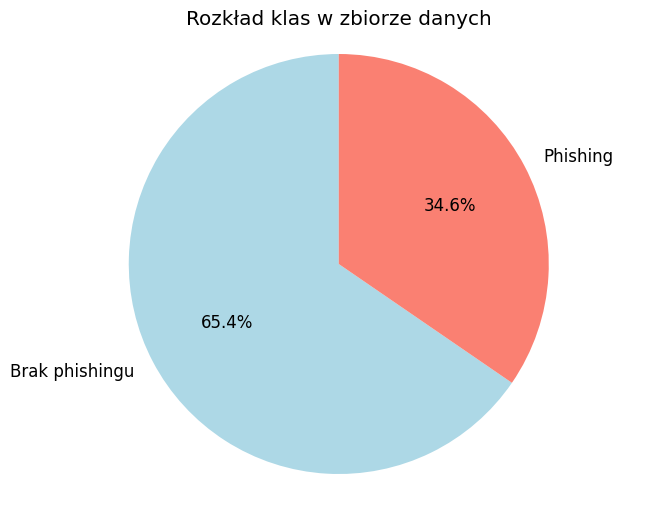


Informacje o zbiorze:
- Łączna liczba próbek: 88,647
- Liczba cech: 111
- Brakujące wartości: 0
- Duplikaty: 1438

Dostępne cechy: 100
Przykładowe cechy: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url']
- Duplikaty: 1438

Dostępne cechy: 100
Przykładowe cechy: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url']


In [7]:
df = pd.read_csv('../data/dataset_full.csv')

print(f"Rozmiar zbioru: {df.shape}")
print(f"Liczba cech: {len(df.columns)-1}")

print(f"\nPierwsze 5 kolumn: {list(df.columns[:5])}")
print(f"Ostatnie 5 kolumn: {list(df.columns[-5:])}")

label_counts = df['phishing'].value_counts()
print(f"\nRozkład etykiet:")
print(f"URL oznaczone jako bez phisingowe: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
print(f"URL oznaczone jako phisingowe: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")

plt.figure(figsize=(8, 6))
colors = ['lightblue', 'salmon']
labels = ['Brak phishingu', 'Phishing']
plt.pie(label_counts.values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Rozkład klas w zbiorze danych')
plt.axis('equal')
plt.show()

print(f"\nInformacje o zbiorze:")
print(f"- Łączna liczba próbek: {len(df):,}")
print(f"- Liczba cech: {len(df.columns)-1}")
print(f"- Brakujące wartości: {df.isnull().sum().sum()}")
print(f"- Duplikaty: {df.duplicated().sum()}")

feature_columns = [col for col in df.columns if col != 'phishing' and col not in [
    'time_response', 'domain_spf', 'asn_ip', 'time_domain_activation', 
    'time_domain_expiration', 'qty_ip_resolved', 'qty_nameservers', 
    'qty_mx_servers', 'ttl_hostname', 'url_google_index', 'domain_google_index'
]]
print(f"\nDostępne cechy: {len(feature_columns)}")
print(f"Przykładowe cechy: {feature_columns[:10]}")

In [8]:
network_dependent_features = [
    'time_response', 'domain_spf', 'asn_ip', 'time_domain_activation', 
    'time_domain_expiration', 'qty_ip_resolved', 'qty_nameservers', 
    'qty_mx_servers', 'ttl_hostname', 'url_google_index', 'domain_google_index'
]

feature_columns = [col for col in df.columns if col != 'phishing' and col not in network_dependent_features]
X = df[feature_columns]
y = df['phishing']           

print(f"\nTypy danych cech:")
data_types = X.dtypes.value_counts()
for dtype, count in data_types.items():
    print(f"  {dtype}: {count} kolumn")

inf_count = np.isinf(X.select_dtypes(include=[np.number])).sum().sum()
nan_count = X.isnull().sum().sum()

print(f"  Wartości nieskończone: {inf_count}")
print(f"  Wartości brakujące: {nan_count}")

if inf_count > 0:
    print("Wykryto wartości nieskończone - zastępowanie medianą...")
    X = X.replace([np.inf, -np.inf], np.nan)

if X.isnull().sum().sum() > 0:
    print("Wykryto wartości brakujące - zastępowanie medianą...")
    X = X.fillna(X.median())

print(f"\nStatystyki cech:")
X_num = X.select_dtypes(include=[np.number])
print(f"  Minimum: {X_num.min().min():.4f}")
print(f"  Maksimum: {X_num.max().max():.4f}")
print(f"  Średnia: {X_num.mean().mean():.4f}")
print(f"  Mediana: {X_num.median().median():.4f}")


Typy danych cech:
  int64: 100 kolumn
  Wartości nieskończone: 0
  Wartości brakujące: 0

Statystyki cech:
  Minimum: -1.0000
  Maksimum: 4165.0000
  Średnia: 0.5481
  Mediana: -1.0000
  Mediana: -1.0000


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,     
    random_state=42,   
    stratify=y          
)

print(f"Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

print(f"\nRozkład klas w zbiorze uczącym:")
train_counts = y_train.value_counts()
print(f"  Brak phishingu: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
print(f"  Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")

print(f"\nRozkład klas w zbiorze testowym:")
test_counts = y_test.value_counts()
print(f"  Brak phishingu: {test_counts[0]:,} ({test_counts[0]/len(y_test)*100:.1f}%)")
print(f"  Phishing: {test_counts[1]:,} ({test_counts[1]/len(y_test)*100:.1f}%)")

Zbiór uczący: 70,917 próbek (80.0%)
Zbiór testowy: 17,730 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Brak phishingu: 46,400 (65.4%)
  Phishing: 24,517 (34.6%)

Rozkład klas w zbiorze testowym:
  Brak phishingu: 11,600 (65.4%)
  Phishing: 6,130 (34.6%)


In [10]:

param_grids = [
    {
        'name': 'Podstawowa siatka',
        'params': {
            'n_estimators': [100, 200, 300],
            'max_depth': [3, 6, 9],
            'learning_rate': [0.1, 0.2, 0.3],
            'subsample': [0.8, 0.9, 1.0]
        }
    },
    {
        'name': 'Rozszerzona siatka',
        'params': {
            'n_estimators': [300, 500, 700],
            'max_depth': [6, 9, 12],
            'learning_rate': [0.05, 0.1, 0.15],
            'subsample': [0.7, 0.8, 0.9],
            'colsample_bytree': [0.8, 0.9, 1.0]
        }
    },
    {
        'name': 'Zaawansowana siatka',
        'params': {
            'n_estimators': [500, 700, 1000],
            'max_depth': [9, 12, 15],
            'learning_rate': [0.01, 0.05, 0.1],
            'subsample': [0.6, 0.7, 0.8],
            'colsample_bytree': [0.6, 0.7, 0.8],
            'reg_alpha': [0, 0.1, 0.5],
            'reg_lambda': [0.1, 1, 2]
        }
    }
]

best_overall_score = 0
best_overall_model = None
best_overall_params = None
best_grid_name = ""

start_time = time.time()

for i, grid_config in enumerate(param_grids):
    grid_name = grid_config['name']
    param_grid = grid_config['params']
    
    print(f"\n--- Siatka {i+1}/{len(param_grids)}: {grid_name} ---")
    
    combinations = 1
    for param_values in param_grid.values():
        combinations *= len(param_values)
    print(f"Liczba kombinacji do przetestowania: {combinations}")
    
    grid_start_time = time.time()
    
    grid_search = GridSearchCV(
        estimator=xgb.XGBClassifier(
            random_state=42, 
            n_jobs=-1, 
            eval_metric='logloss',
            verbosity=0
        ),
        param_grid=param_grid,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0,
        return_train_score=True
    )
    
    grid_search.fit(X_train, y_train)
    
    grid_time = time.time() - grid_start_time
    
    print(f"Czas wykonania siatki: {grid_time:.2f} sekund")
    print(f"Najlepszy wynik CV ROC-AUC: {grid_search.best_score_:.4f}")
    print(f"Najlepsze parametry: {grid_search.best_params_}")
    
    if grid_search.best_score_ > best_overall_score:
        best_overall_score = grid_search.best_score_
        best_overall_model = grid_search.best_estimator_
        best_overall_params = grid_search.best_params_
        best_grid_name = grid_name
        print(f"Nowy najlepszy model z siatki: {grid_name}")

total_time = time.time() - start_time
best_model = best_overall_model

print(f"Całkowity czas strojenia: {total_time:.2f} sekund ({total_time/60:.1f} minut)")
print(f"Najlepszy wynik CV ROC-AUC: {best_overall_score:.4f}")
print(f"Najlepsze parametry:")
for param, value in best_overall_params.items():
    print(f"   {param}: {value}")

if best_overall_score >= 0.90:
    print("Bardzo dobra wydajność modelu (≥90%)")
elif best_overall_score >= 0.85:
    print("Dobra wydajność modelu (≥85%)")
else:
    print("Wydajność modelu wymaga poprawy (<85%)")


--- Siatka 1/3: Podstawowa siatka ---
Liczba kombinacji do przetestowania: 81
Czas wykonania siatki: 744.32 sekund
Najlepszy wynik CV ROC-AUC: 0.9836
Najlepsze parametry: {'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 200, 'subsample': 0.9}
Nowy najlepszy model z siatki: Podstawowa siatka

--- Siatka 2/3: Rozszerzona siatka ---
Liczba kombinacji do przetestowania: 243
Czas wykonania siatki: 744.32 sekund
Najlepszy wynik CV ROC-AUC: 0.9836
Najlepsze parametry: {'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 200, 'subsample': 0.9}
Nowy najlepszy model z siatki: Podstawowa siatka

--- Siatka 2/3: Rozszerzona siatka ---
Liczba kombinacji do przetestowania: 243
Czas wykonania siatki: 4163.28 sekund
Najlepszy wynik CV ROC-AUC: 0.9838
Najlepsze parametry: {'colsample_bytree': 0.9, 'learning_rate': 0.05, 'max_depth': 9, 'n_estimators': 500, 'subsample': 0.9}
Nowy najlepszy model z siatki: Rozszerzona siatka

--- Siatka 3/3: Zaawansowana siatka ---
Liczba kombinacji do przetesto


Dokładność:     0.9437 (94.37%)
Precyzja:       0.9298 (92.98%)
Czułość:        0.9055 (90.55%)
Miara F1:       0.9175
ROC-AUC:        0.9844
CV ROC-AUC:     0.9846 (±0.0014)

Szczegółowy raport klasyfikacji:
                    precision    recall  f1-score   support

Bez phisingowe URL       0.95      0.96      0.96     11600
   Phishingowe URL       0.93      0.91      0.92      6130

          accuracy                           0.94     17730
         macro avg       0.94      0.93      0.94     17730
      weighted avg       0.94      0.94      0.94     17730


Analiza macierzy pomyłek:
  Prawdziwie negatywne (TN): 11,181
  Fałszywie pozytywne (FP): 419
  Fałszywie negatywne (FN): 579
  Prawdziwie pozytywne (TP): 5,551

Wykres analizy zapisany: ../static/plots/xgboost_analysis.png

Wykres analizy zapisany: ../static/plots/xgboost_analysis.png


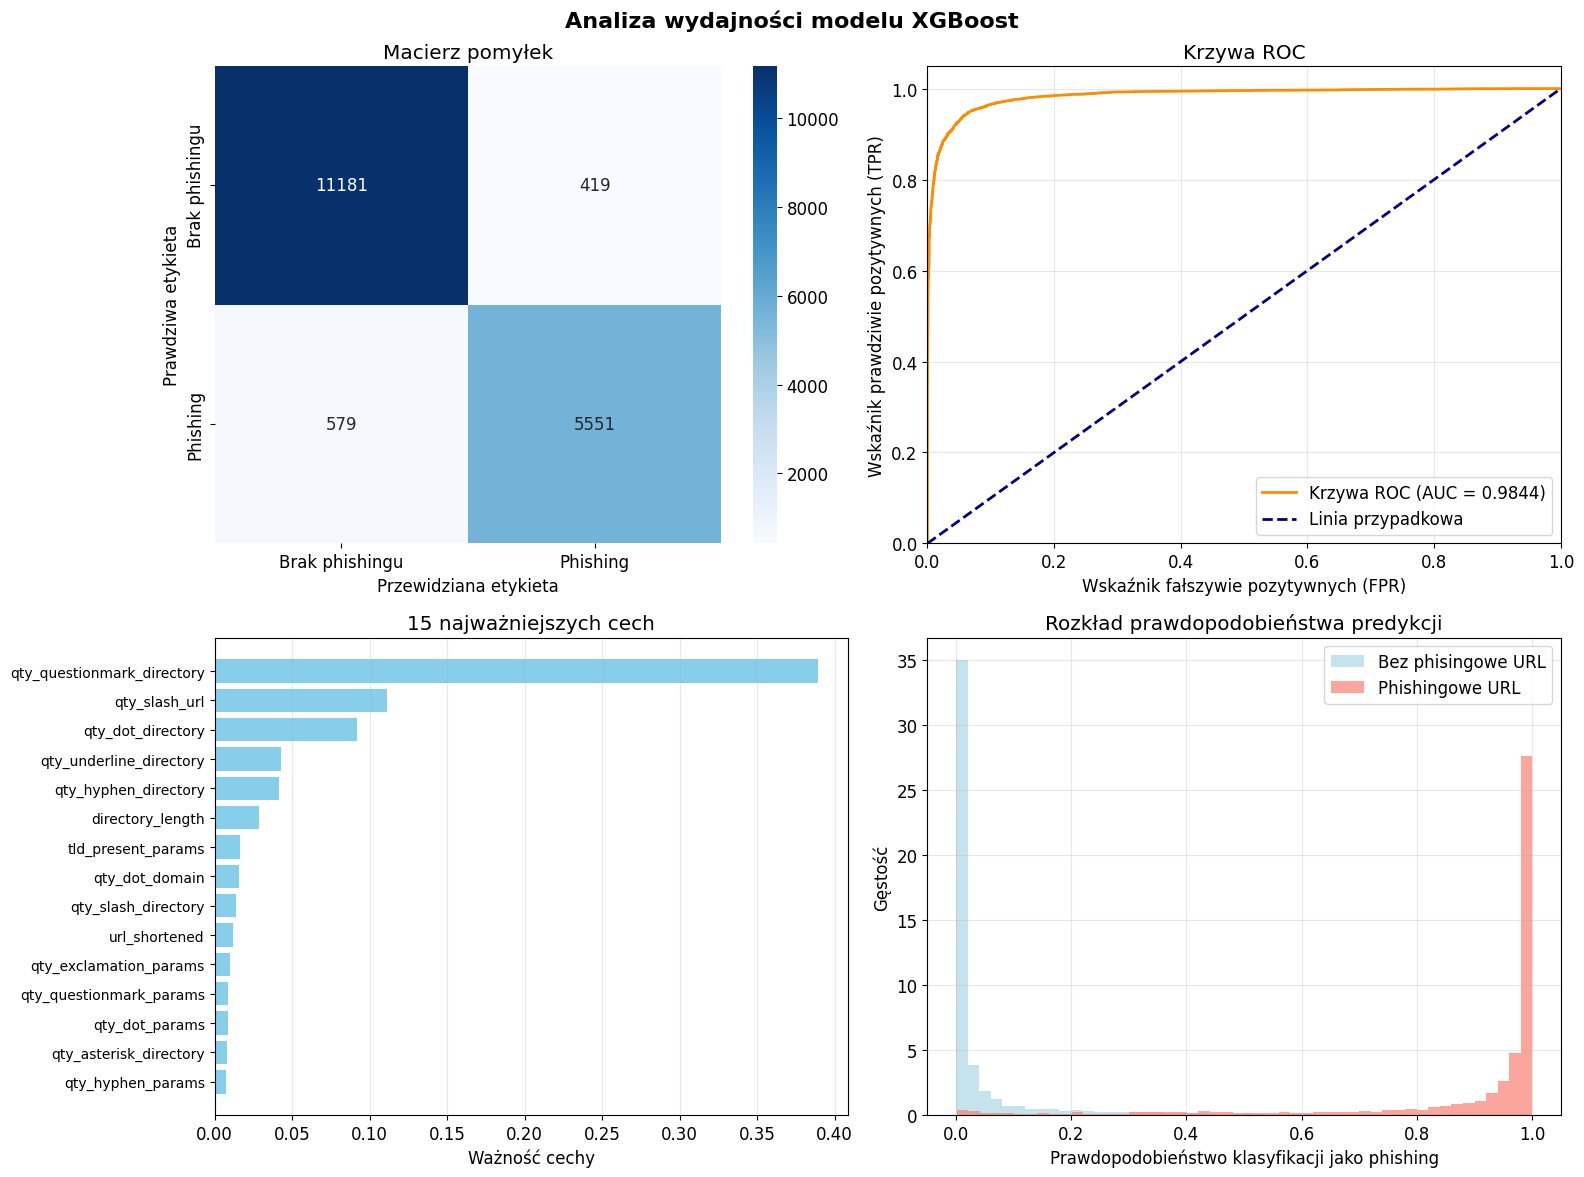


10 najważniejszych cech:
   1. qty_questionmark_directory: 0.3892
   2. qty_slash_url: 0.1110
   3. qty_dot_directory: 0.0921
   4. qty_underline_directory: 0.0426
   5. qty_hyphen_directory: 0.0414
   6. directory_length: 0.0285
   7. tld_present_params: 0.0162
   8. qty_dot_domain: 0.0156
   9. qty_slash_directory: 0.0135
  10. url_shortened: 0.0116

Wydajność modelu: BARDZO DOBRA


In [11]:

y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_pred_proba)

cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring='roc_auc')

print("\n" + "="*50)
print("="*50)
print(f"Dokładność:     {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precyzja:       {precision:.4f} ({precision*100:.2f}%)")
print(f"Czułość:        {recall:.4f} ({recall*100:.2f}%)")
print(f"Miara F1:       {f1:.4f}")
print(f"ROC-AUC:        {auc_roc:.4f}")
print(f"CV ROC-AUC:     {cv_scores.mean():.4f} (±{cv_scores.std()*2:.4f})")

print("\nSzczegółowy raport klasyfikacji:")
target_names = ['Bez phisingowe URL', 'Phishingowe URL']
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"\nAnaliza macierzy pomyłek:")
print(f"  Prawdziwie negatywne (TN): {tn:,}")
print(f"  Fałszywie pozytywne (FP): {fp:,}")
print(f"  Fałszywie negatywne (FN): {fn:,}")
print(f"  Prawdziwie pozytywne (TP): {tp:,}")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Analiza wydajności modelu XGBoost', fontsize=16, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Brak phishingu', 'Phishing'], 
            yticklabels=['Brak phishingu', 'Phishing'], 
            ax=axes[0,0])
axes[0,0].set_title('Macierz pomyłek')
axes[0,0].set_ylabel('Prawdziwa etykieta')
axes[0,0].set_xlabel('Przewidziana etykieta')

fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[0,1].plot(fpr, tpr, color='darkorange', lw=2, 
               label=f'Krzywa ROC (AUC = {auc_roc:.4f})')
axes[0,1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', 
               label='Linia przypadkowa')
axes[0,1].set_xlim([0.0, 1.0])
axes[0,1].set_ylim([0.0, 1.05])
axes[0,1].set_xlabel('Wskaźnik fałszywie pozytywnych (FPR)')
axes[0,1].set_ylabel('Wskaźnik prawdziwie pozytywnych (TPR)')
axes[0,1].set_title('Krzywa ROC')
axes[0,1].legend(loc="lower right")
axes[0,1].grid(True, alpha=0.3)

feature_importance = best_model.feature_importances_
top_indices = np.argsort(feature_importance)[-15:]
top_features = [X.columns[i] for i in top_indices]
top_importance = feature_importance[top_indices]

axes[1,0].barh(range(len(top_features)), top_importance, color='skyblue')
axes[1,0].set_yticks(range(len(top_features)))
axes[1,0].set_yticklabels(top_features, fontsize=10)
axes[1,0].set_xlabel('Ważność cechy')
axes[1,0].set_title('15 najważniejszych cech')
axes[1,0].grid(True, alpha=0.3, axis='x')

axes[1,1].hist(y_pred_proba[y_test == 0], bins=50, alpha=0.7, 
               label='Bez phisingowe URL', color='lightblue', density=True)
axes[1,1].hist(y_pred_proba[y_test == 1], bins=50, alpha=0.7, 
               label='Phishingowe URL', color='salmon', density=True)
axes[1,1].set_xlabel('Prawdopodobieństwo klasyfikacji jako phishing')
axes[1,1].set_ylabel('Gęstość')
axes[1,1].set_title('Rozkład prawdopodobieństwa predykcji')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()

plot_filename = f"{PLOTS_DIR}/xgboost_analysis.png"
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"\nWykres analizy zapisany: {plot_filename}")

plt.show()

print(f"\n10 najważniejszych cech:")
sorted_features = sorted(zip(X.columns, feature_importance), 
                        key=lambda x: x[1], reverse=True)
for i, (feature, importance) in enumerate(sorted_features[:10]):
    print(f"  {i+1:2d}. {feature}: {importance:.4f}")

print(f"\n{'='*50}")
print(f"{'='*50}")

high_performance_metrics = [
    accuracy >= 0.95, 
    precision >= 0.95, 
    recall >= 0.95, 
    f1 >= 0.95, 
    auc_roc >= 0.95
]

if all(high_performance_metrics):
    performance_level = "DOSKONAŁA"
elif accuracy >= 0.90 and auc_roc >= 0.90:
    performance_level = "BARDZO DOBRA"
elif accuracy >= 0.85 and auc_roc >= 0.85:
    performance_level = "DOBRA"
else:
    performance_level = "WYMAGA POPRAWY"

print(f"Wydajność modelu: {performance_level}")

In [12]:

import pickle
import os

os.makedirs('../models', exist_ok=True)
os.makedirs('../data', exist_ok=True)

model_data = {
    'model': best_model,
    'scaler': None,  
    'feature_names': X.columns.tolist(),
    'best_params': best_overall_params,
    'metrics': {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc,
        'cv_auc_mean': cv_scores.mean(),
        'cv_auc_std': cv_scores.std()
    }
}

model_path = '../models/xgboost_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_data, f)

results_df = pd.DataFrame({
    'Metryka': ['Dokładność', 'Precyzja', 'Czułość', 'Miara F1', 'AUC-ROC'],
    'Wartość': [accuracy, precision, recall, f1, auc_roc]
})

results_path = '../data/xgboost_results.csv'
results_df.to_csv(results_path, index=False)

performance_summary = {
    'typ_modelu': 'XGBoost',
    'dokładność': accuracy,
    'precyzja': precision,
    'czułość': recall,
    'miara_f1': f1,
    'roc_auc': auc_roc,
    'cv_auc_średnia': cv_scores.mean(),
    'cv_auc_odchylenie': cv_scores.std(),
    'liczba_cech': len(X.columns),
    'próbki_uczące': len(X_train),
    'próbki_testowe': len(X_test),
    'czas_strojenia': total_time,
    'najlepsza_siatka': best_grid_name
}

print(f"\n{'='*50}")
print(f"{'='*50}")
for key, value in performance_summary.items():
    if isinstance(value, float):
        print(f"{key.replace('_', ' ').title()}: {value:.4f}")
    else:
        print(f"{key.replace('_', ' ').title()}: {value}")

print(f"- Główna analiza: {PLOTS_DIR}/xgboost_analysis.png")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Brak phishingu', 'Phishing'], 
            yticklabels=['Brak phishingu', 'Phishing'])
plt.title('Macierz pomyłek - XGBoost')
plt.ylabel('Prawdziwa etykieta')
plt.xlabel('Przewidziana etykieta')
plt.savefig(f'{PLOTS_DIR}/xgboost_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Krzywa ROC (AUC = {auc_roc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Wskaźnik fałszywie pozytywnych')
plt.ylabel('Wskaźnik prawdziwie pozytywnych')
plt.title('Krzywa ROC - XGBoost')
plt.legend(loc="lower right")
plt.savefig(f'{PLOTS_DIR}/xgboost_roc_curve.png', dpi=300, bbox_inches='tight')
plt.close()


Typ Modelu: XGBoost
Dokładność: 0.9437
Precyzja: 0.9298
Czułość: 0.9055
Miara F1: 0.9175
Roc Auc: 0.9844
Cv Auc Średnia: 0.9846
Cv Auc Odchylenie: 0.0007
Liczba Cech: 100
Próbki Uczące: 70917
Próbki Testowe: 17730
Czas Strojenia: 20481.6706
Najlepsza Siatka: Zaawansowana siatka
- Główna analiza: ../static/plots/xgboost_analysis.png
